# PCA Section: Does dimension reduction help clustering?
**STAT 6250 Final Project, Group 5** | PCA section (Aniket Ghosh)

This notebook answers **Key Question 2** from our proposal:

> *Does prior dimension reduction enhance cluster stability and separation, or does it discard critical financial context?*

Plan:
1. Reproduce the exact preprocessing from `Kmeans_GmmComparison.ipynb` so our data matrix is identical.
2. Show why PCA is reasonable here (the 17 variables are heavily correlated, and one is a near-exact sum of two others).
3. Run PCA, choose how many components to keep, and interpret the loadings.
4. Re-run K-Means on the PC scores and compare with the raw-data K-Means clusters on **agreement**, **separation**, and **stability**.
5. Interpret the clusters (risky vs. profitable) and note how PCA interacts with GMM.

## 1. Data and preprocessing (copied from `Kmeans_GmmComparison.ipynb`)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from scipy.optimize import linear_sum_assignment

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42

In [2]:
# Load dataset
df = pd.read_csv("CC GENERAL.csv")
print(df.shape)

(8950, 18)


In [3]:
# --- Preprocessing copied from Kmeans_GmmComparison.ipynb ---
# Create a copy of the dataset
data = df.copy()

# Remove duplicate rows
data = data.drop_duplicates()

# Remove columns that should not influence clustering
data = data.drop(columns=["CUST_ID"], errors="ignore")

# Separate numerical and categorical columns
numerical_cols = data.select_dtypes(include=["int64", "float64"]).columns
categorical_cols = data.select_dtypes(include=["object", "category"]).columns

# Handle missing numerical values using the median
num_imputer = SimpleImputer(strategy="median")
data[numerical_cols] = num_imputer.fit_transform(data[numerical_cols])

# Handle missing categorical values (none in this dataset, kept for consistency)
cat_imputer = SimpleImputer(strategy="most_frequent")
if len(categorical_cols) > 0:
    data[categorical_cols] = cat_imputer.fit_transform(data[categorical_cols])

# Encode categorical variables (none in this dataset, kept for consistency)
data = pd.get_dummies(data, columns=categorical_cols, drop_first=False, dtype=int)

print(data.shape)

(8950, 17)


In [4]:
# Standardize features (same as teammate's notebook)
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(data), columns=data.columns, index=data.index)
print(X_scaled.shape)

(8950, 17)


In [5]:
# Reproduce the raw-data K-Means solution (k = 3) from the teammate's notebook
# Same settings: n_clusters=3, random_state=42, n_init=10
kmeans_raw = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
labels_raw = kmeans_raw.fit_predict(X_scaled)
sil_raw = silhouette_score(X_scaled, labels_raw)

print("Cluster sizes:", pd.Series(labels_raw).value_counts().sort_index().to_dict())
print(f"Silhouette (raw K-Means, k=3): {sil_raw:.4f}")

Cluster sizes: {0: 1275, 1: 6114, 2: 1561}
Silhouette (raw K-Means, k=3): 0.2510


The cluster sizes (1275 / 6114 / 1561) and silhouette score (0.251) match the teammate's notebook exactly, so every comparison below is against the same baseline.

## 2. Why PCA? Correlation and redundancy in the variables
PCA is useful when variables are strongly correlated, because a few combinations of them can carry most of the information.

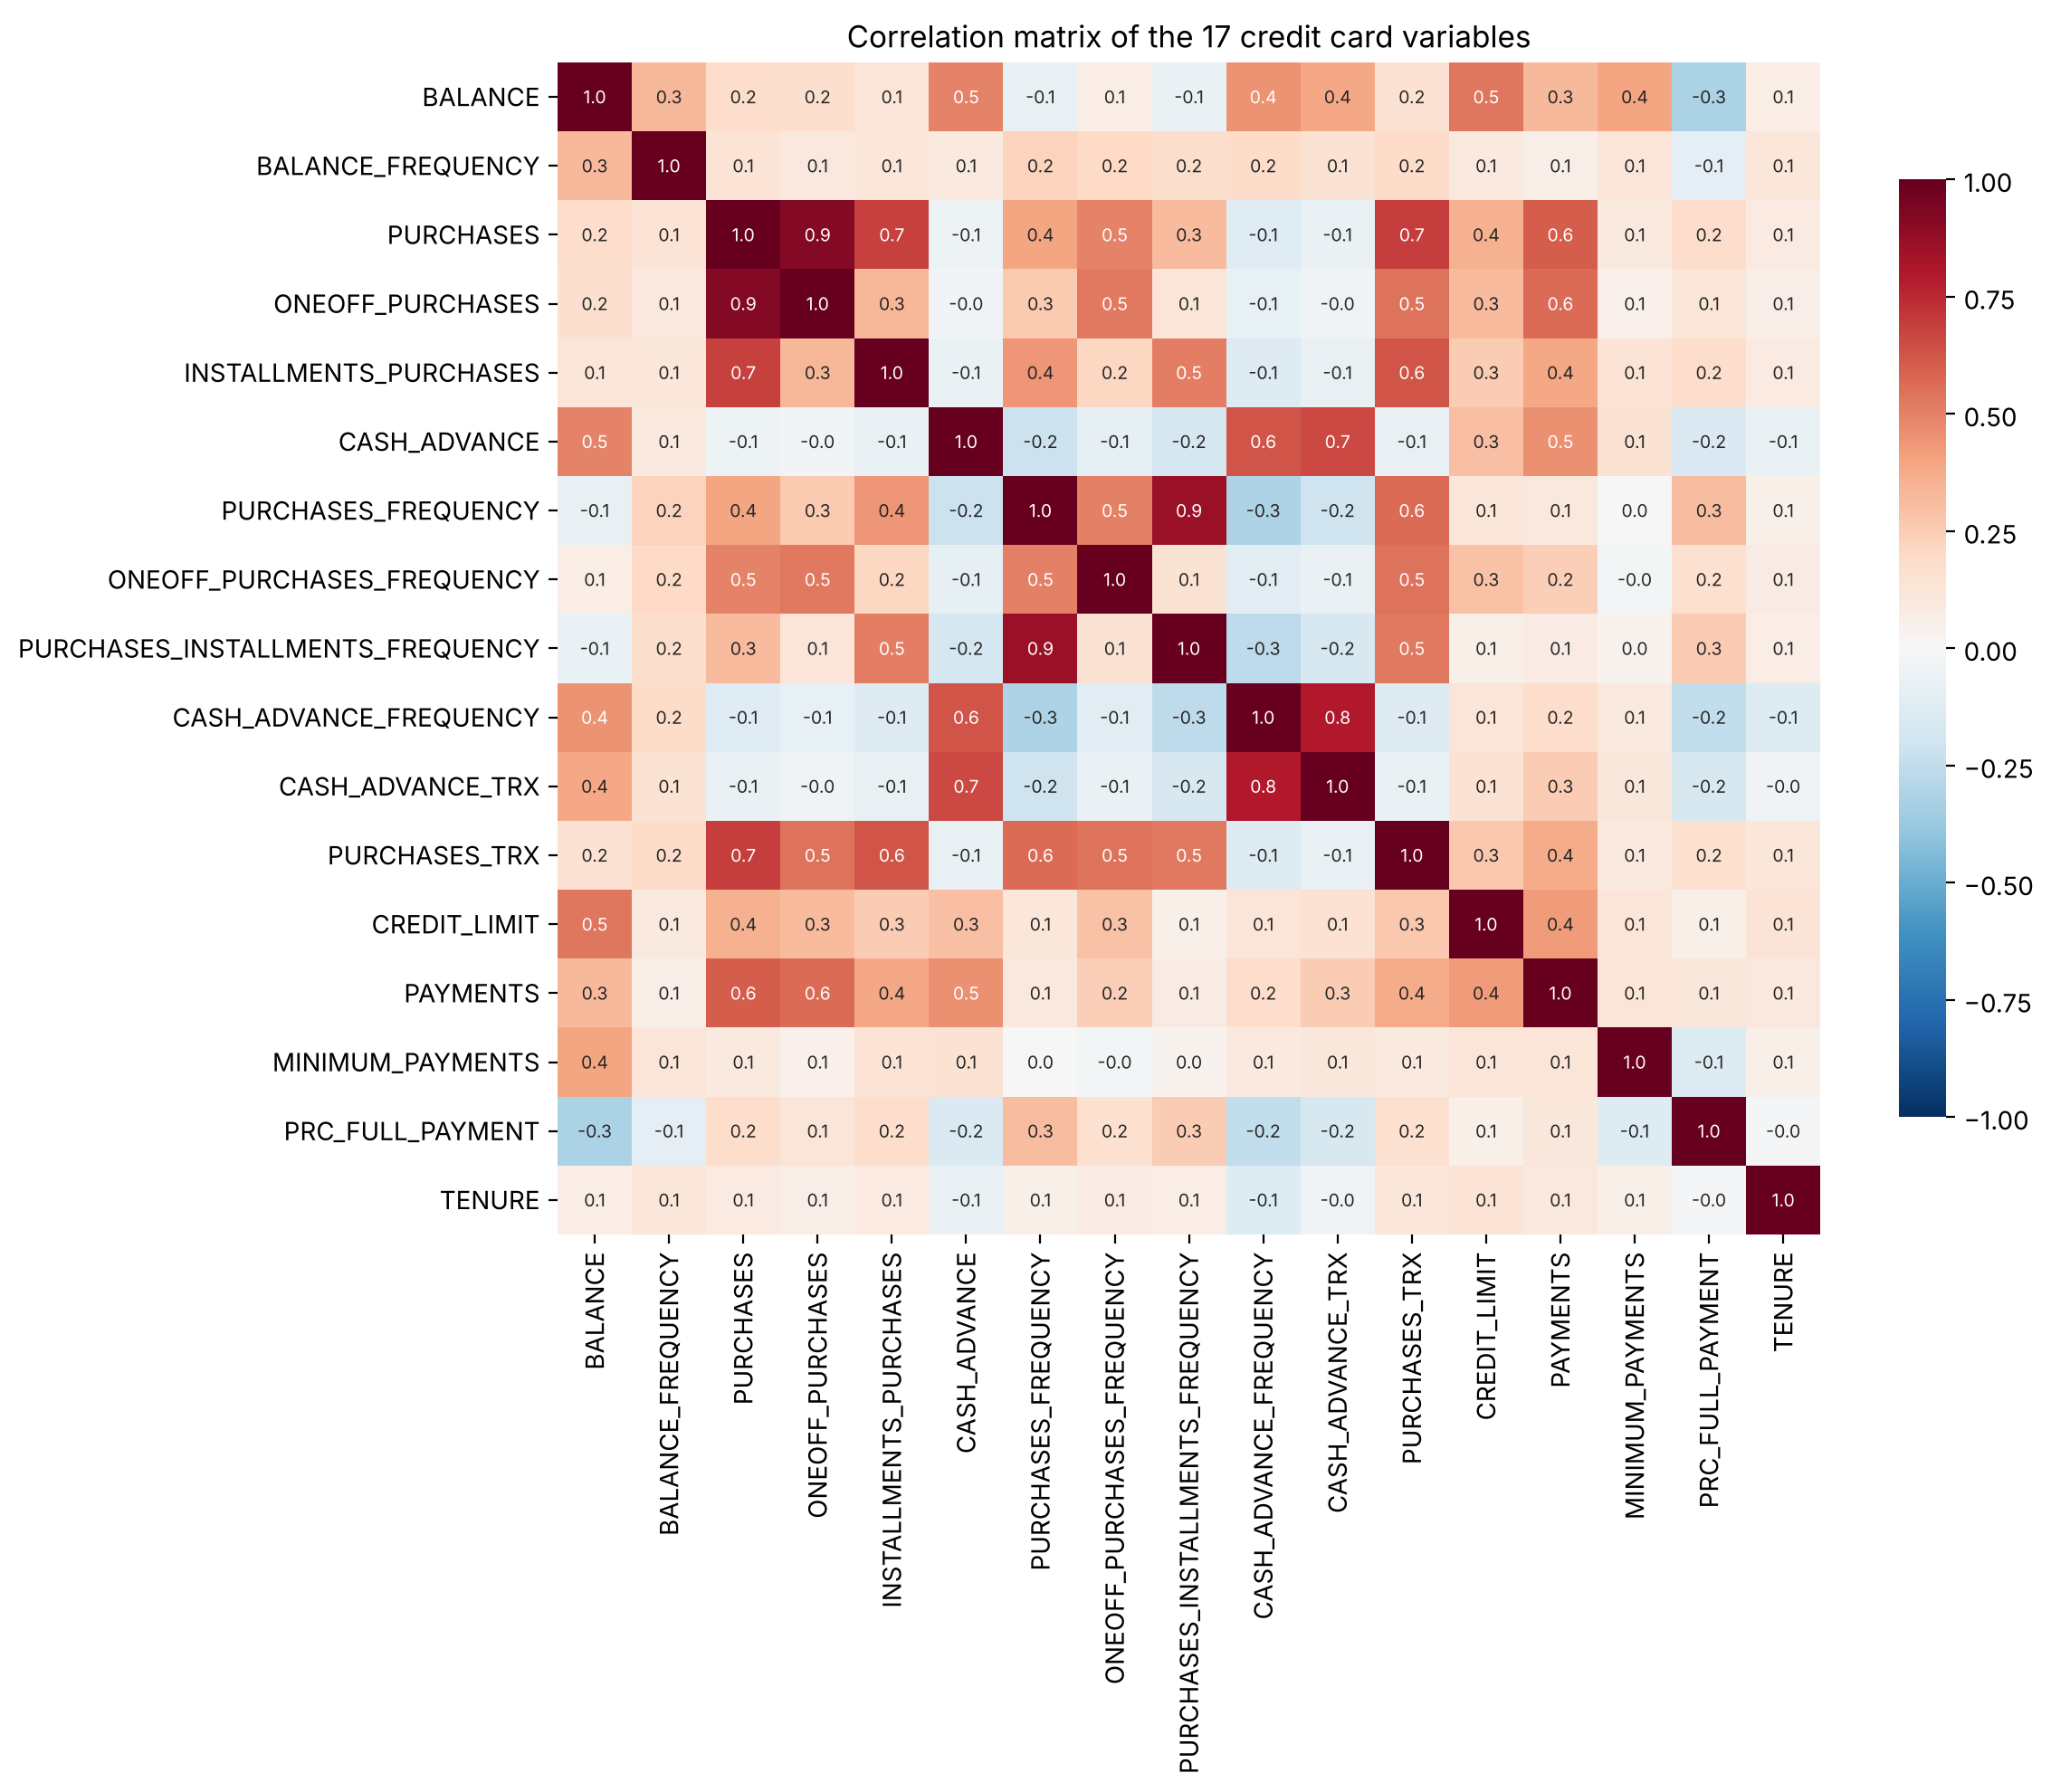

Variable pairs with |r| >= 0.5: 18
PURCHASES               ONEOFF_PURCHASES                    0.92
PURCHASES_FREQUENCY     PURCHASES_INSTALLMENTS_FREQUENCY    0.86
CASH_ADVANCE_FREQUENCY  CASH_ADVANCE_TRX                    0.80
PURCHASES               PURCHASES_TRX                       0.69
                        INSTALLMENTS_PURCHASES              0.68
CASH_ADVANCE            CASH_ADVANCE_TRX                    0.66
                        CASH_ADVANCE_FREQUENCY              0.63
INSTALLMENTS_PURCHASES  PURCHASES_TRX                       0.63
PURCHASES               PAYMENTS                            0.60
PURCHASES_FREQUENCY     PURCHASES_TRX                       0.57
ONEOFF_PURCHASES        PAYMENTS                            0.57
                        PURCHASES_TRX                       0.55
dtype: float64


In [6]:
corr = data.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f",
            annot_kws={"size": 7}, cbar_kws={"shrink": 0.8})
plt.title("Correlation matrix of the 17 credit card variables")
plt.tight_layout()
plt.show()

# Count strongly correlated pairs
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
strong = upper.stack()
strong = strong[strong.abs() >= 0.5].sort_values(key=abs, ascending=False)
print(f"Variable pairs with |r| >= 0.5: {len(strong)}")
print(strong.round(2).head(12))

In [7]:
# PURCHASES is (almost exactly) ONEOFF_PURCHASES + INSTALLMENTS_PURCHASES
diff = (data["PURCHASES"] - data["ONEOFF_PURCHASES"] - data["INSTALLMENTS_PURCHASES"]).abs()
print(f"Share of customers where PURCHASES = ONEOFF + INSTALLMENTS (within $0.01): {(diff < 0.01).mean():.1%}")

Share of customers where PURCHASES = ONEOFF + INSTALLMENTS (within $0.01): 99.8%


**Takeaway:** There are clear blocks of correlated variables: a *purchase* block (purchase amounts, frequencies, transaction counts) and a *cash advance* block (cash advance amount, frequency, transactions). Also, `PURCHASES` is the sum of `ONEOFF_PURCHASES` and `INSTALLMENTS_PURCHASES` for 99.8% of customers, so the 17 variables really span only about 16 dimensions. This redundancy is what motivates PCA.

## 3. Principal Component Analysis

In [8]:
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_scaled)

eigenvalues = pca_full.explained_variance_
var_ratio = pca_full.explained_variance_ratio_
cum_var = np.cumsum(var_ratio)

pca_table = pd.DataFrame({
    "Eigenvalue": eigenvalues.round(3),
    "Prop. variance": var_ratio.round(3),
    "Cumulative": cum_var.round(3),
}, index=[f"PC{i+1}" for i in range(len(eigenvalues))])
pca_table

,Eigenvalue,Prop. variance,Cumulative
PC1,4.641,0.273,0.273
PC2,3.454,0.203,0.476
PC3,1.498,0.088,0.564
PC4,1.272,0.075,0.639
PC5,1.058,0.062,0.701
PC6,0.976,0.057,0.759
PC7,0.830,0.049,0.808
PC8,0.731,0.043,0.851
PC9,0.646,0.038,0.888
PC10,0.524,0.031,0.919


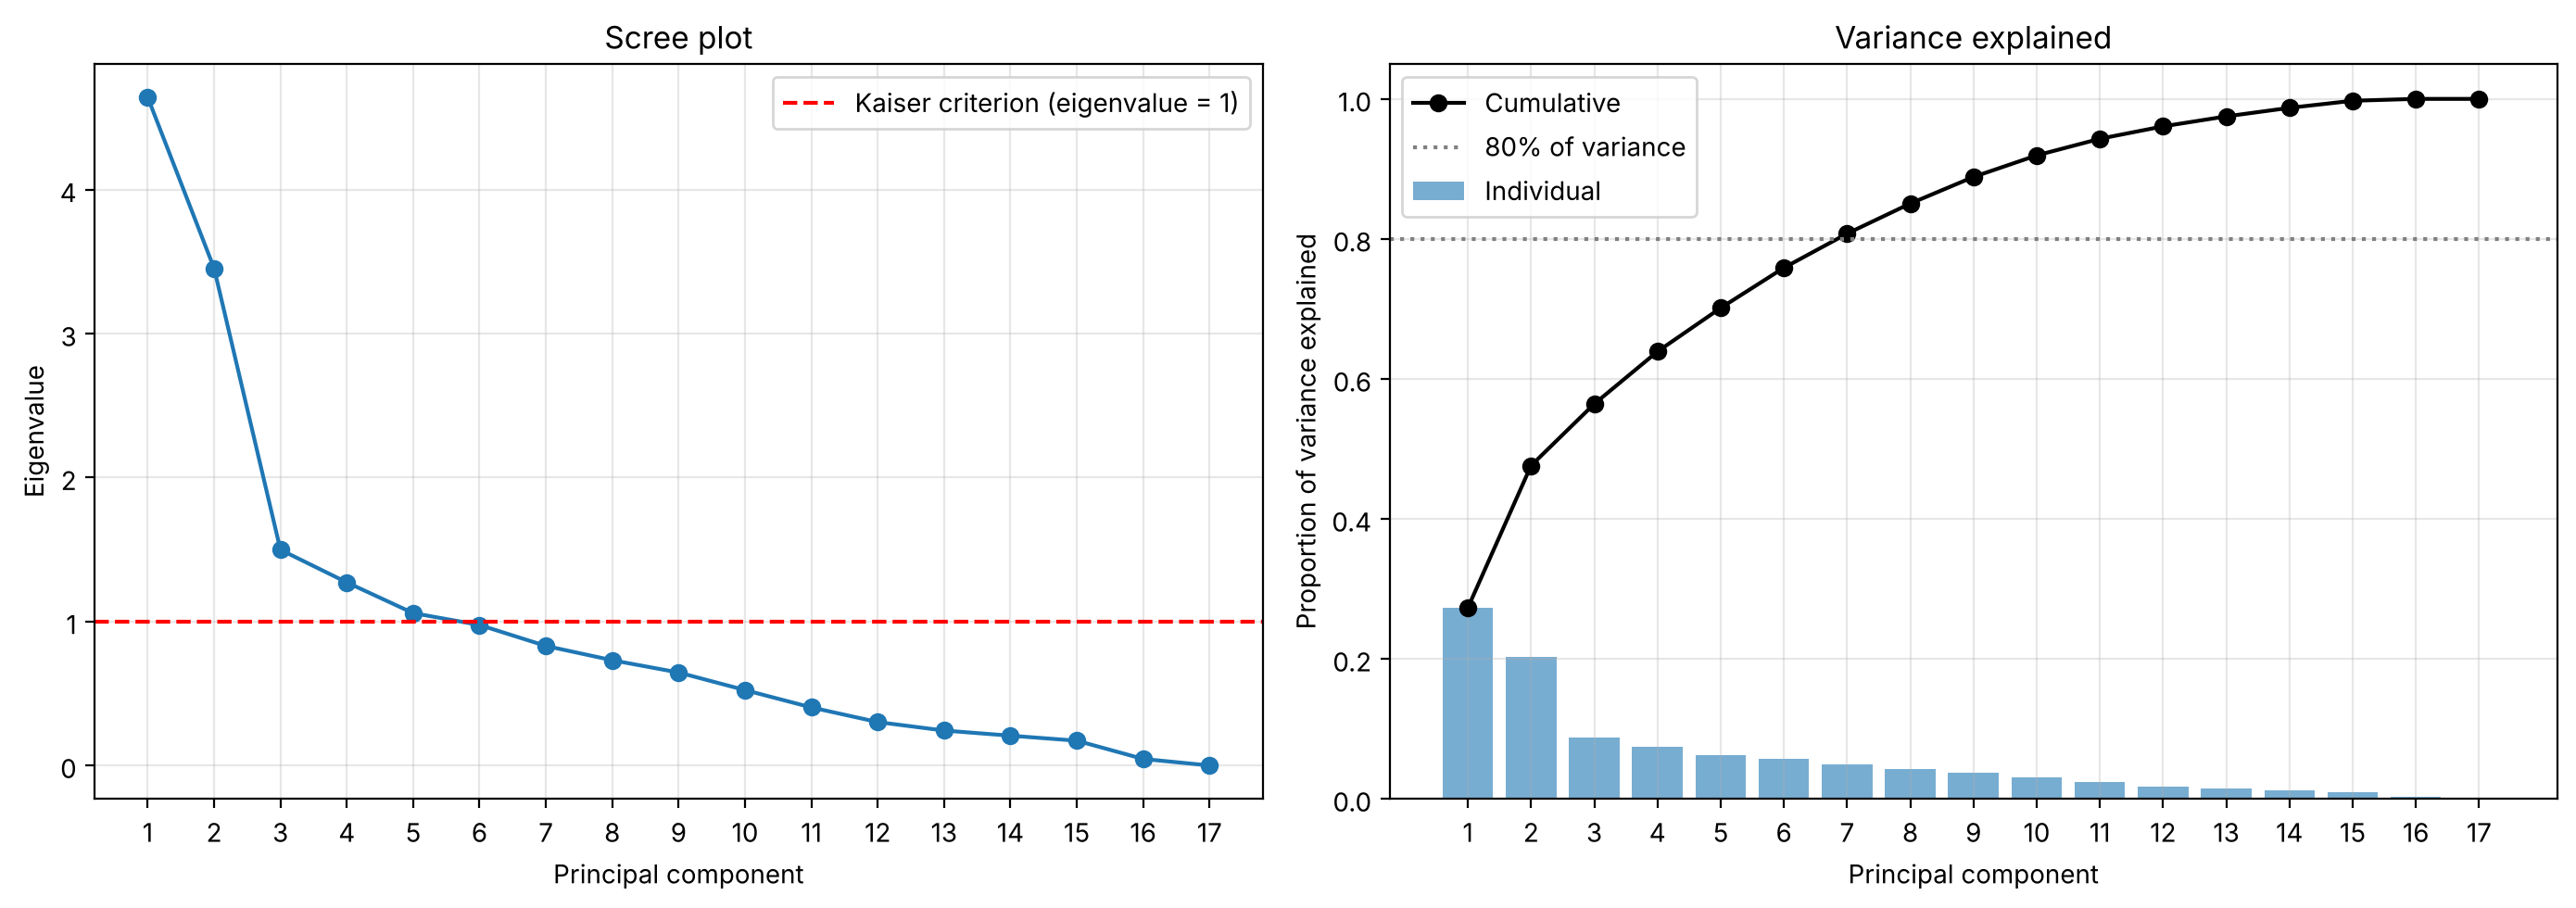

Kaiser criterion keeps 5 PCs (70.1% of variance)
80% variance rule keeps 7 PCs (80.8% of variance)
PC1 + PC2 explain 47.6% of variance
Smallest eigenvalue: 1.17e-05  (the PURCHASES redundancy)


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pcs = np.arange(1, len(eigenvalues) + 1)

axes[0].plot(pcs, eigenvalues, marker="o")
axes[0].axhline(1, color="red", linestyle="--", label="Kaiser criterion (eigenvalue = 1)")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Eigenvalue")
axes[0].set_title("Scree plot")
axes[0].set_xticks(pcs)
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].bar(pcs, var_ratio, alpha=0.6, label="Individual")
axes[1].plot(pcs, cum_var, marker="o", color="black", label="Cumulative")
axes[1].axhline(0.80, color="gray", linestyle=":", label="80% of variance")
axes[1].set_xlabel("Principal component")
axes[1].set_ylabel("Proportion of variance explained")
axes[1].set_title("Variance explained")
axes[1].set_xticks(pcs)
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

n_kaiser = int((eigenvalues > 1).sum())
n_80 = int(np.argmax(cum_var >= 0.80) + 1)
print(f"Kaiser criterion keeps {n_kaiser} PCs ({cum_var[n_kaiser-1]:.1%} of variance)")
print(f"80% variance rule keeps {n_80} PCs ({cum_var[n_80-1]:.1%} of variance)")
print(f"PC1 + PC2 explain {cum_var[1]:.1%} of variance")
print(f"Smallest eigenvalue: {eigenvalues[-1]:.2e}  (the PURCHASES redundancy)")

**Choosing the number of components.**
- The scree plot has a sharp drop after PC2, then flattens out.
- The **Kaiser criterion** (eigenvalue > 1) keeps **5 PCs**, which explain about 70% of the variance.
- The **80% rule** keeps **7 PCs**.
- The last eigenvalue is essentially 0, confirming that one direction carries no information at all.

Rather than committing to one rule, Section 4 treats the number of PCs as a tuning parameter and checks how clustering changes as we keep 2, 3, ..., 10 components.

### 3.1 Interpreting the loadings

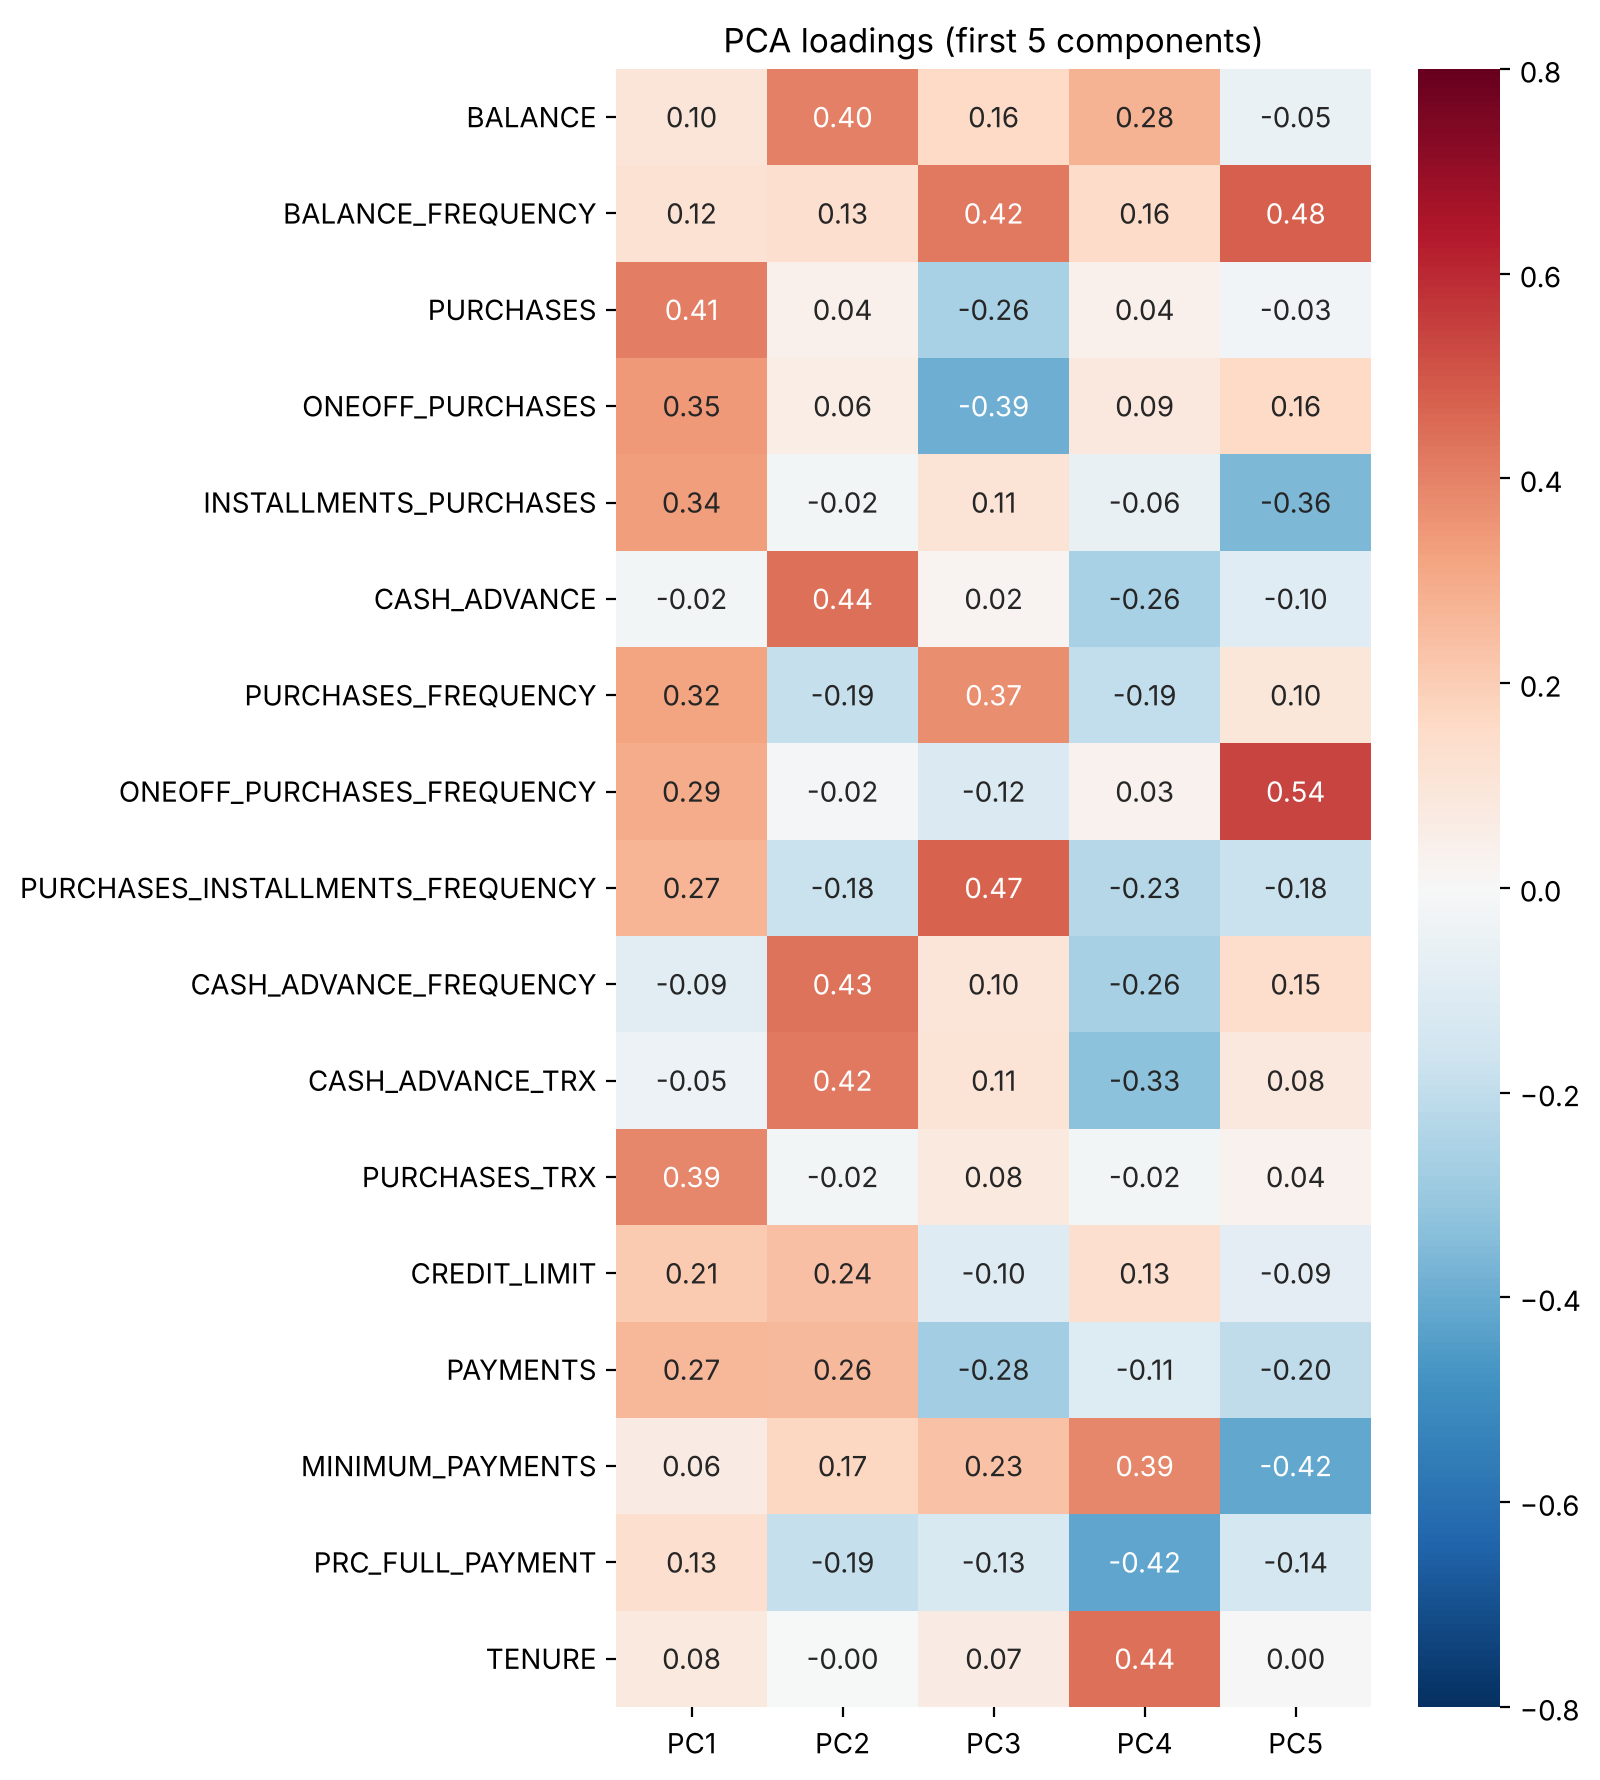

PC1: PURCHASES (+0.41), PURCHASES_TRX (+0.39), ONEOFF_PURCHASES (+0.35), INSTALLMENTS_PURCHASES (+0.34)
PC2: CASH_ADVANCE (+0.44), CASH_ADVANCE_FREQUENCY (+0.43), CASH_ADVANCE_TRX (+0.42), BALANCE (+0.40)
PC3: PURCHASES_INSTALLMENTS_FREQUENCY (+0.47), BALANCE_FREQUENCY (+0.42), ONEOFF_PURCHASES (-0.39), PURCHASES_FREQUENCY (+0.37)
PC4: TENURE (+0.44), PRC_FULL_PAYMENT (-0.42), MINIMUM_PAYMENTS (+0.39), CASH_ADVANCE_TRX (-0.33)
PC5: ONEOFF_PURCHASES_FREQUENCY (+0.54), BALANCE_FREQUENCY (+0.48), MINIMUM_PAYMENTS (-0.42), INSTALLMENTS_PURCHASES (-0.36)


In [10]:
n_show = 5
loadings = pd.DataFrame(
    pca_full.components_[:n_show].T,
    index=X_scaled.columns,
    columns=[f"PC{i+1}" for i in range(n_show)],
)

plt.figure(figsize=(8, 9))
sns.heatmap(loadings, cmap="RdBu_r", center=0, annot=True, fmt=".2f", vmin=-0.8, vmax=0.8)
plt.title("PCA loadings (first 5 components)")
plt.tight_layout()
plt.show()

for pc in loadings.columns:
    top = loadings[pc].abs().sort_values(ascending=False).head(4).index
    print(f"{pc}: " + ", ".join(f"{v} ({loadings.loc[v, pc]:+.2f})" for v in top))

**Interpretation** (the sign of a component is arbitrary; what matters is which variables move together):

| PC | Variance | Main variables | Interpretation |
|---|---|---|---|
| PC1 | 27% | Purchases, purchase transactions, one-off and installment purchases, purchase frequency | **Overall purchasing activity**: how much the customer uses the card to buy things |
| PC2 | 20% | Cash advance amount / frequency / transactions, balance | **Cash advance and revolving balance**: borrowing cash on the card and carrying a balance (the "risk" axis) |
| PC3 | 9% | Installment frequency, purchase frequency, balance frequency (+) vs. one-off purchases (−) | **Installment vs. one-off style** of purchasing |
| PC4 | 7% | Tenure, minimum payments (+) vs. % full payment (−) | **Account age and repayment behavior** |
| PC5 | 6% | One-off frequency, balance frequency (+) vs. minimum payments, installments (−) | **Frequent small one-off usage** |

The first two components line up directly with our proposal's framing: **PC1 ≈ spending (potentially profitable transactors)** and **PC2 ≈ cash-advance borrowing with high balances (potentially risky revolvers)**.

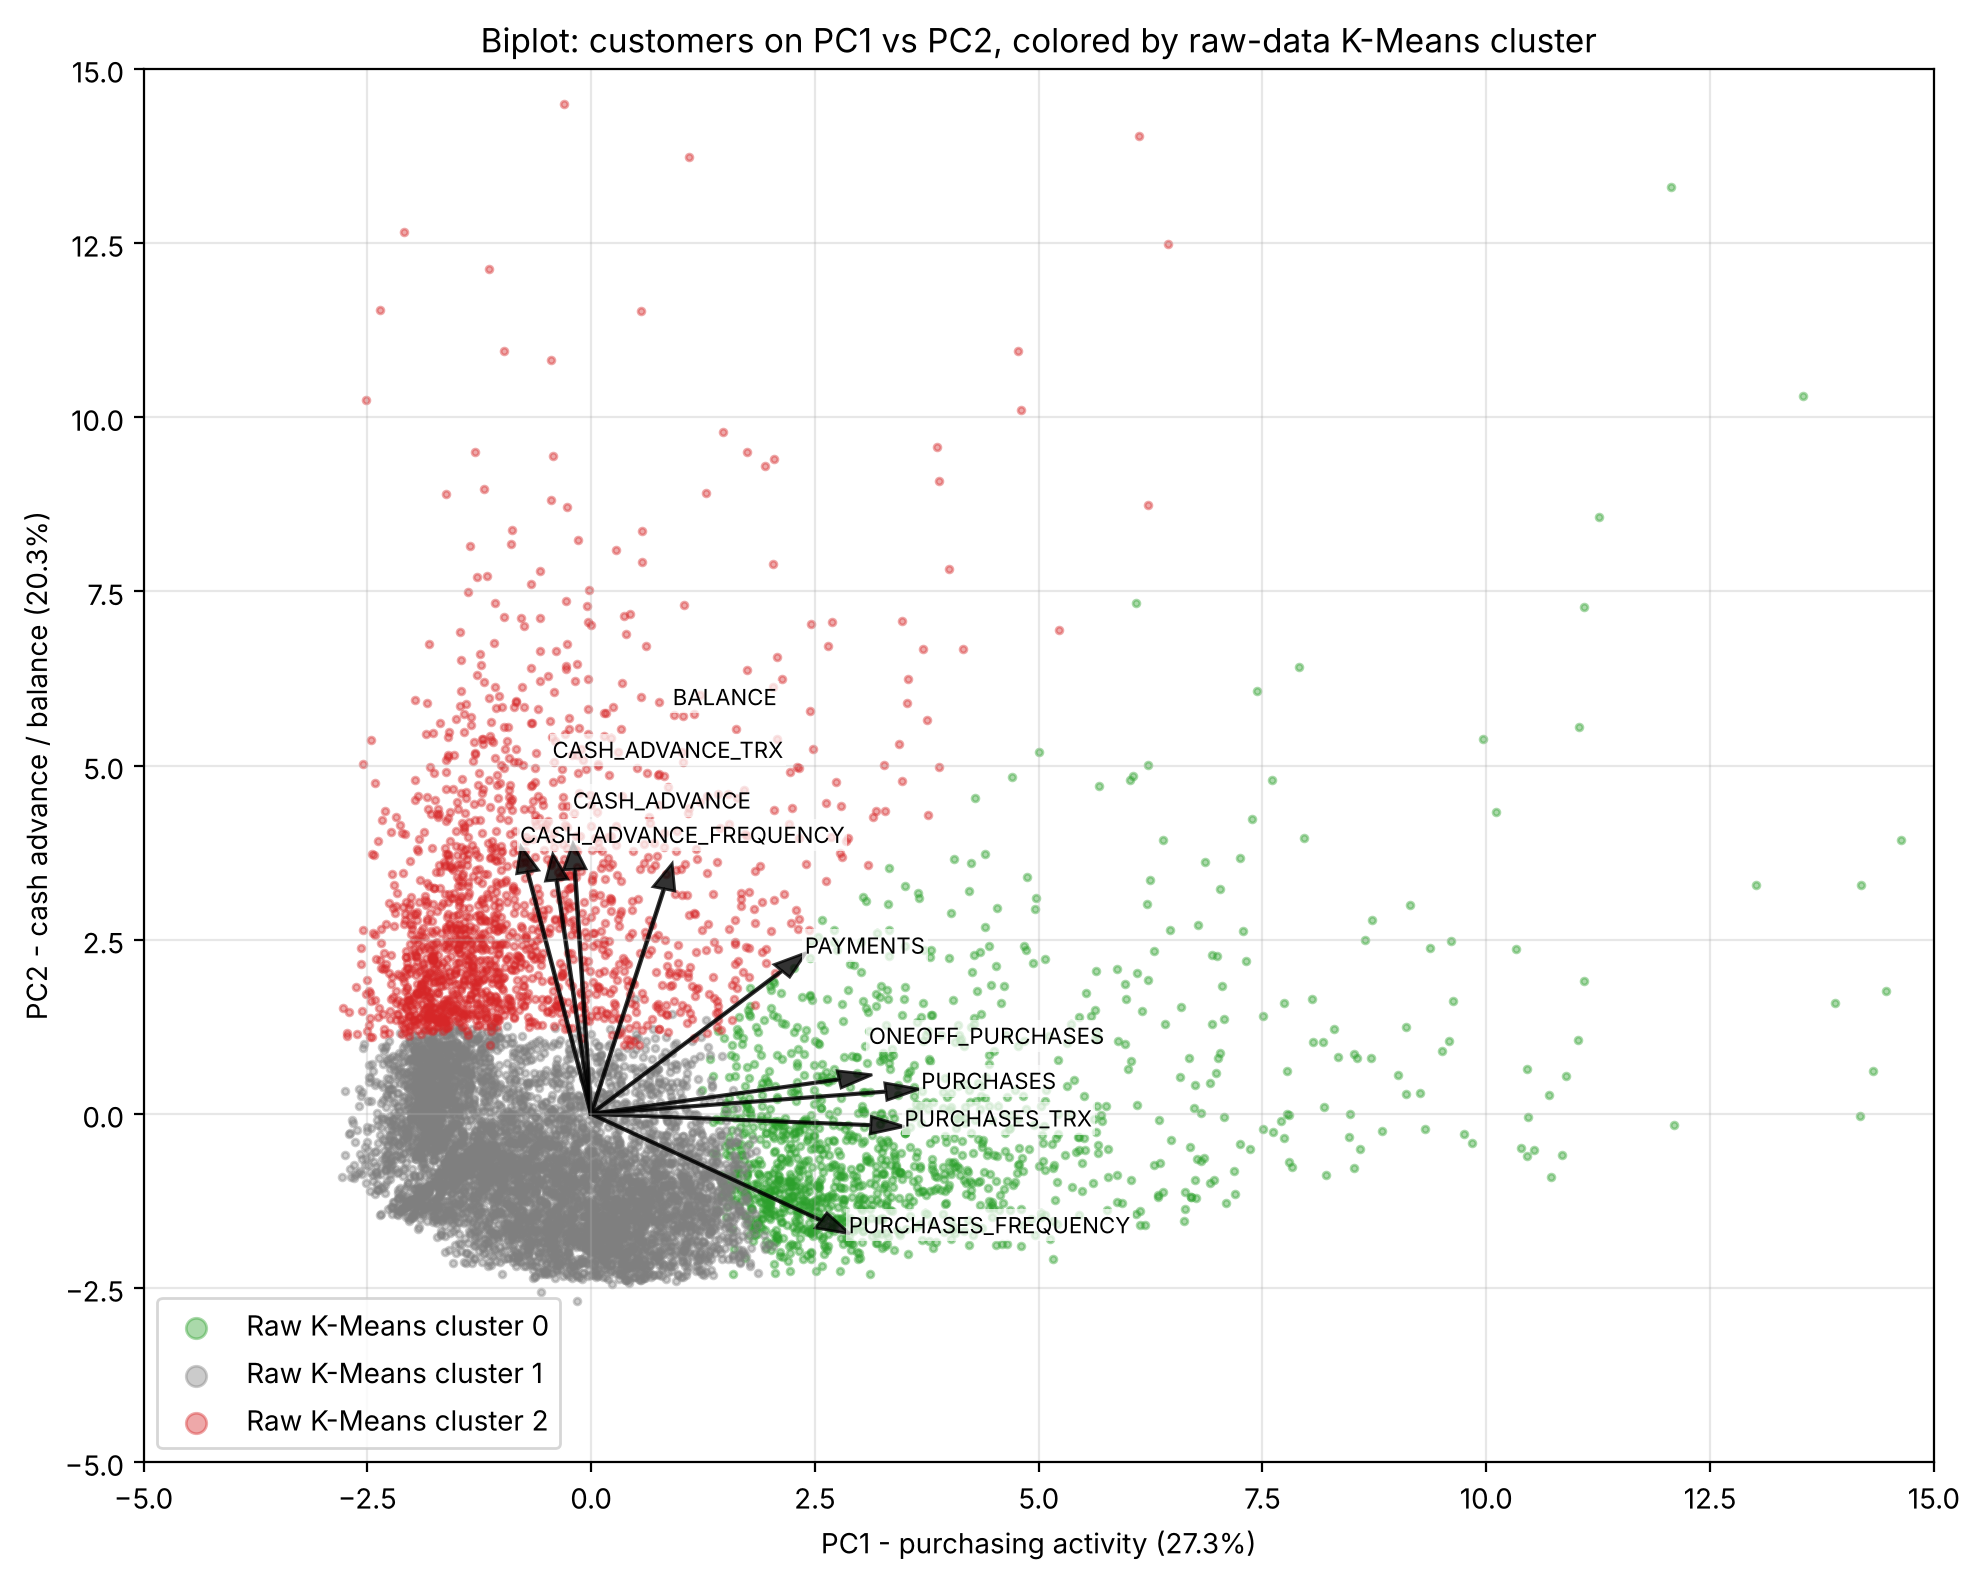

In [11]:
scores_full = pca_full.transform(X_scaled)

fig, ax = plt.subplots(figsize=(10, 8))
palette = {0: "tab:green", 1: "tab:gray", 2: "tab:red"}
for c in sorted(np.unique(labels_raw)):
    m = labels_raw == c
    ax.scatter(scores_full[m, 0], scores_full[m, 1], s=6, alpha=0.4, color=palette[c], label=f"Raw K-Means cluster {c}")

# Biplot arrows for the most important variables
scale = 8
top_vars = loadings[["PC1", "PC2"]].pow(2).sum(axis=1).sort_values(ascending=False).head(9).index
placed = []
for v in top_vars:
    x, y = loadings.loc[v, "PC1"] * scale, loadings.loc[v, "PC2"] * scale
    ax.arrow(0, 0, x, y, color="black", width=0.02, head_width=0.25, alpha=0.8)
    tx, ty = x * 1.12, y * 1.12
    # nudge labels upward so overlapping arrow labels stay readable
    while any(abs(tx - px) < 2.5 and abs(ty - py) < 0.45 for px, py in placed):
        ty += 0.45
    placed.append((tx, ty))
    ax.text(tx, ty, v, fontsize=8, bbox=dict(facecolor="white", alpha=0.7, edgecolor="none", pad=1))

ax.set_xlabel(f"PC1 - purchasing activity ({var_ratio[0]:.1%})")
ax.set_ylabel(f"PC2 - cash advance / balance ({var_ratio[1]:.1%})")
ax.set_title("Biplot: customers on PC1 vs PC2, colored by raw-data K-Means cluster")
ax.set_xlim(-5, 15)
ax.set_ylim(-5, 15)
ax.legend(markerscale=3)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The raw-data K-Means clusters separate cleanly along the first two PCs: one cluster extends along the **purchasing** direction (PC1), one along the **cash advance** direction (PC2), and the large third cluster sits near the origin (low activity). So even though K-Means was run on all 17 variables, the structure it found lives mostly in a 2-dimensional subspace. This is the first hint that PCA does not throw away the information the clusters depend on.

(Axes are clipped to [-5, 15] for readability; a small number of extreme customers lie outside.)

## 4. Clustering on PC scores vs. raw data
For each number of retained components *q* = 2, ..., 10 we run K-Means (k = 3, same settings as the raw analysis) on the first *q* PC scores and record:

- **ARI vs. raw**: Adjusted Rand Index between the PCA-based clusters and the raw-data clusters. A value of 1 means identical partitions and 0 means chance-level agreement. This measures whether PCA *distorts* the clusters.
- **Silhouette (PC space)**: separation measured in the reduced space the clustering actually used.
- **Silhouette (original space)**: separation of the same partition measured in the full 17-variable standardized space. This is the **fair** comparison against the raw silhouette of 0.251, because silhouette scores computed in fewer dimensions are mechanically inflated.

In [12]:
results = []
pc_labels = {}
for q in range(2, 11):
    pca_q = PCA(n_components=q, random_state=RANDOM_STATE)
    Z = pca_q.fit_transform(X_scaled)
    lab = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10).fit_predict(Z)
    pc_labels[q] = lab
    results.append({
        "PCs kept (q)": q,
        "Variance kept": pca_q.explained_variance_ratio_.sum(),
        "ARI vs raw": adjusted_rand_score(labels_raw, lab),
        "Silhouette (PC space)": silhouette_score(Z, lab),
        "Silhouette (original space)": silhouette_score(X_scaled, lab),
    })

comparison = pd.DataFrame(results).set_index("PCs kept (q)")
raw_row = pd.DataFrame({"Variance kept": [1.0], "ARI vs raw": [1.0],
                        "Silhouette (PC space)": [np.nan], "Silhouette (original space)": [sil_raw]},
                       index=pd.Index(["raw (17 vars)"], name="PCs kept (q)"))
comparison = pd.concat([raw_row, comparison])
comparison.round(3)

,Variance kept,ARI vs raw,Silhouette (PC space),Silhouette (original space)
PCs kept (q),,,,
raw (17 vars),1.000,1.000,NaN,0.251
2,0.476,0.914,0.452,0.246
3,0.564,0.930,0.380,0.248
4,0.639,0.405,0.315,0.207
5,0.701,0.960,0.316,0.250
6,0.759,0.970,0.295,0.250
7,0.808,0.980,0.285,0.252
8,0.851,0.982,0.274,0.251
9,0.888,0.980,0.262,0.250


**What the table shows:**
- With **5 or more PCs**, the clusters are almost identical to the raw-data clusters (ARI ≈ 0.96–0.98), and their separation in the original space is the same (silhouette ≈ 0.25).
- With just **2–3 PCs** (about 48–56% of the variance), agreement is still above 0.9.
- So PCA does **not** discard the context that defines the clusters. But it also does **not** improve true separation: the original-space silhouette stays at about 0.25 throughout.
- The much higher silhouettes in the PC-space column (up to 0.46 at q = 2) are an artifact of measuring distance in fewer dimensions, not a real improvement. This is an easy mistake to make when comparing methods.
- **q = 4 is an exception** (ARI ≈ 0.4): in that space K-Means settles on a different 3-way split. This sensitivity is itself a sign that the k = 3 solution is not perfectly stable, which motivates the stability analysis below.

### 4.1 Cluster stability (bootstrap)
To measure stability, we resample customers with replacement (bootstrap). For each resample we refit the pipeline on the resample (PCA first when applicable, then K-Means with k = 3), assign *all* customers to the new clusters, and compute the ARI against the full-data solution. A stable method gives ARI close to 1 on every resample.

In [13]:
def bootstrap_stability(X, q=None, n_boot=50, k=3, seed=0):
    """ARI between the full-data K-Means partition and partitions fit on bootstrap resamples.
    If q is given, PCA (q components) is refit on each resample before clustering."""
    X = np.asarray(X)

    def fit_predict(X_fit, X_all, rs):
        if q is not None:
            p = PCA(n_components=q, random_state=RANDOM_STATE).fit(X_fit)
            X_fit, X_all = p.transform(X_fit), p.transform(X_all)
        km = KMeans(n_clusters=k, random_state=rs, n_init=10).fit(X_fit)
        return km.predict(X_all)

    ref = fit_predict(X, X, RANDOM_STATE)
    rng = np.random.default_rng(seed)
    aris = []
    for b in range(n_boot):
        idx = rng.choice(len(X), size=len(X), replace=True)
        aris.append(adjusted_rand_score(ref, fit_predict(X[idx], X, b)))
    return np.array(aris)

stability = {"raw": bootstrap_stability(X_scaled)}
for q in [2, 3, 5, 7]:
    stability[f"{q} PCs"] = bootstrap_stability(X_scaled, q=q)

stab_table = pd.DataFrame({
    name: {"Mean ARI": a.mean(), "Median ARI": np.median(a), "5th percentile": np.percentile(a, 5),
           "Minimum ARI": a.min(),
           "Share of resamples that collapse (ARI < 0.5)": (a < 0.5).mean()}
    for name, a in stability.items()
}).T
stab_table.round(3)

,Mean ARI,Median ARI,5th percentile,Minimum ARI,Share of resamples that collapse (ARI < 0.5)
raw,0.722,0.926,0.132,0.112,0.32
2 PCs,0.912,0.923,0.791,0.710,0.00
3 PCs,0.900,0.935,0.781,0.180,0.04
5 PCs,0.821,0.941,0.146,0.117,0.16
7 PCs,0.709,0.923,0.118,0.098,0.36


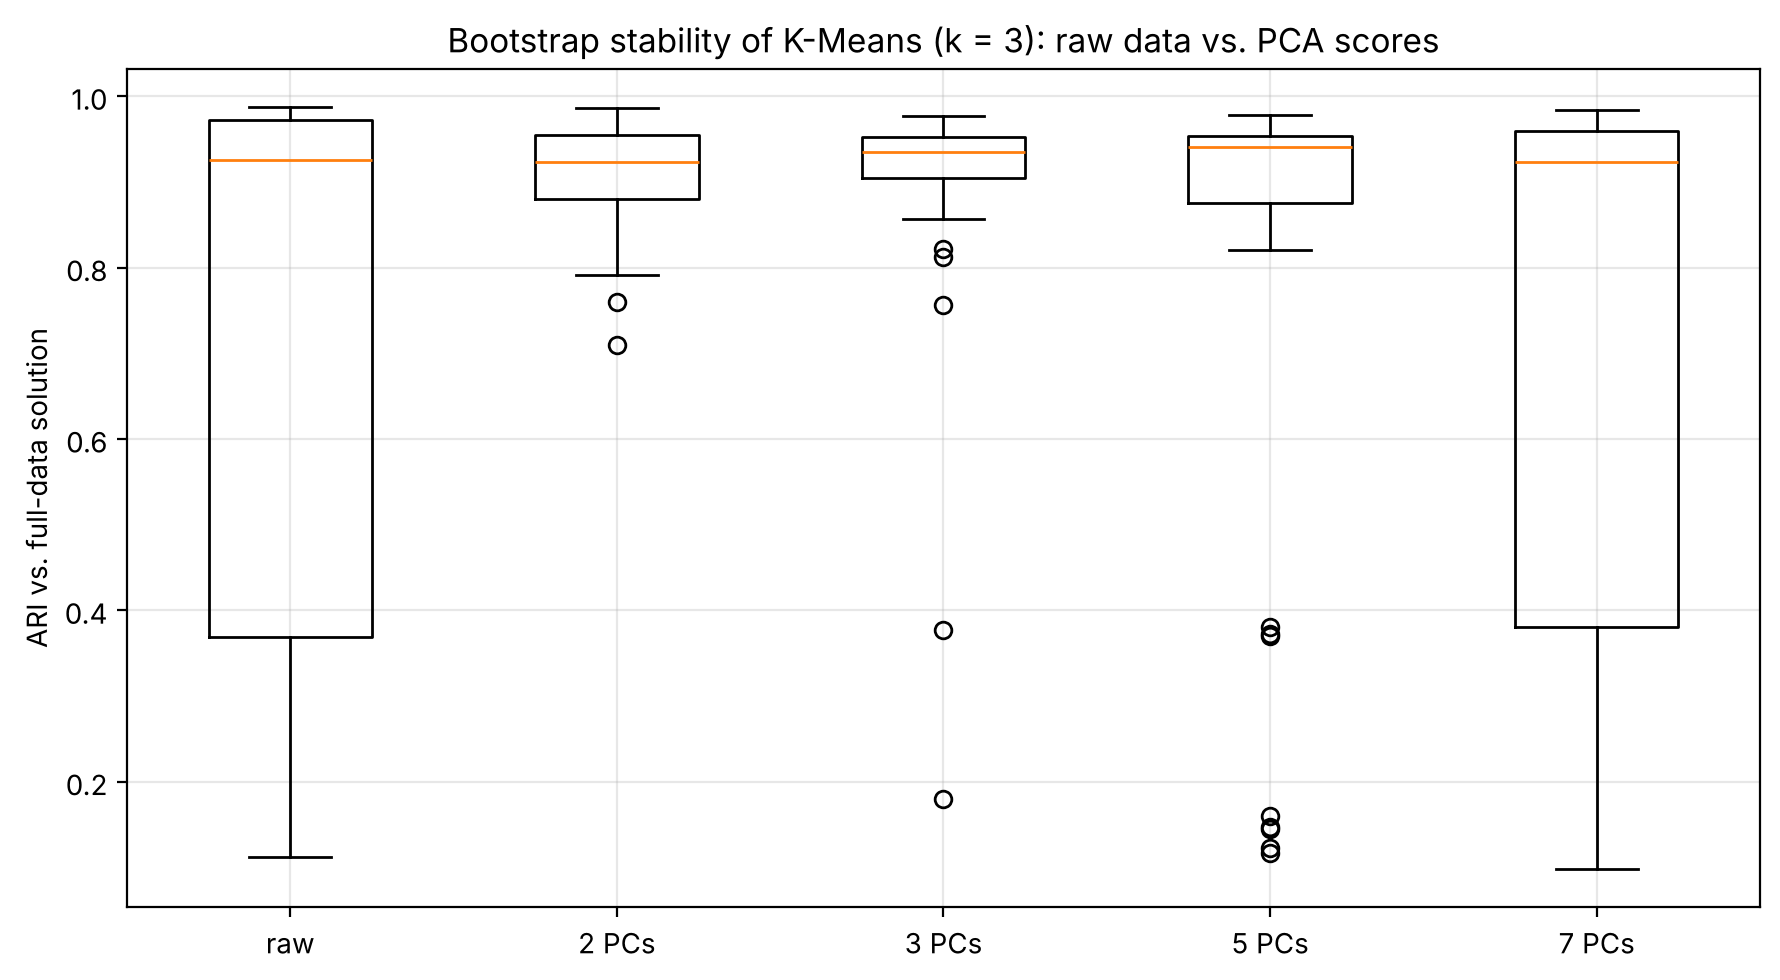

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(list(stability.values()))
ax.set_xticks(range(1, len(stability) + 1), list(stability.keys()))
ax.set_ylabel("ARI vs. full-data solution")
ax.set_title("Bootstrap stability of K-Means (k = 3): raw data vs. PCA scores")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Stability is where PCA helps.**
- When the raw-data solution is reproduced, it is reproduced well (median ARI ≈ 0.93). But in about **a third of resamples (32%)**, raw-data K-Means collapses into a completely different partition (ARI < 0.5).
- Keeping fewer components steadily reduces these collapses: 36% with 7 PCs, 16% with 5 PCs, 4% with 3 PCs, and **none with 2 PCs** (worst case still ARI ≈ 0.71).
- Combined with the previous table (ARI > 0.9 vs. raw), this means low-dimensional PCA gives **essentially the same customer segments, found far more reliably**.
- Keeping 7 PCs is no more stable than the raw data, because the later components mostly add noise that K-Means can latch onto.

### 4.2 What the clusters mean: risky vs. profitable customers

In [15]:
# Use 3 PCs as the PCA-based solution (good stability, ARI > 0.9 with raw)
Q_MAIN = 3
labels_pca = pc_labels[Q_MAIN]

# Relabel PCA clusters to best match raw cluster numbers (cluster labels are arbitrary)
ct = pd.crosstab(labels_raw, labels_pca)
row, col = linear_sum_assignment(-ct.values)
mapping = {ct.columns[c]: ct.index[r] for r, c in zip(row, col)}
labels_pca = np.vectorize(mapping.get)(labels_pca)

cluster_names = {0: "Active transactors", 1: "Low-activity users", 2: "Cash-advance revolvers"}

ct = pd.crosstab(pd.Series(labels_raw, name="Raw K-Means").map(cluster_names),
                 pd.Series(labels_pca, name=f"PCA ({Q_MAIN} PCs) K-Means").map(cluster_names),
                 margins=True)
ct

PCA (3 PCs) K-Means,Active transactors,Cash-advance revolvers,Low-activity users,All
Raw K-Means,,,,
Active transactors,1174,2,99,1275
Cash-advance revolvers,5,1552,4,1561
Low-activity users,10,73,6031,6114
All,1189,1627,6134,8950


In [16]:
profile_vars = ["BALANCE", "PURCHASES", "PURCHASES_FREQUENCY", "PURCHASES_TRX", "CASH_ADVANCE",
                "CASH_ADVANCE_FREQUENCY", "CREDIT_LIMIT", "PAYMENTS", "MINIMUM_PAYMENTS", "PRC_FULL_PAYMENT"]

def profile(labels):
    p = data.assign(Cluster=pd.Series(labels, index=data.index).map(cluster_names)).groupby("Cluster")[profile_vars].mean()
    p.insert(0, "Size", pd.Series(labels).map(cluster_names).value_counts())
    return p.loc[list(cluster_names.values())]

print("Raw-data K-Means cluster means (original units):")
display(profile(labels_raw).round(2))
print(f"PCA ({Q_MAIN} PCs) K-Means cluster means (original units):")
display(profile(labels_pca).round(2))

Raw-data K-Means cluster means (original units):


,Size,BALANCE,PURCHASES,PURCHASES_FREQUENCY,PURCHASES_TRX,CASH_ADVANCE,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT
Cluster,,,,,,,,,,,
Active transactors,1275,2182.35,4187.02,0.95,55.69,449.75,0.06,7642.78,4075.53,1227.92,0.30
Low-activity users,6114,807.72,496.06,0.46,8.48,339.00,0.07,3267.02,907.45,530.07,0.15
Cash-advance revolvers,1561,4023.79,389.05,0.23,5.64,3917.25,0.45,6729.47,3053.94,1765.20,0.03


PCA (3 PCs) K-Means cluster means (original units):


,Size,BALANCE,PURCHASES,PURCHASES_FREQUENCY,PURCHASES_TRX,CASH_ADVANCE,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT
Cluster,,,,,,,,,,,
Active transactors,1189,2273.59,4386.76,0.95,57.60,490.82,0.07,7759.13,4324.84,1277.33,0.30
Low-activity users,6134,788.84,515.30,0.47,8.87,323.16,0.07,3300.75,911.65,501.83,0.16
Cash-advance revolvers,1627,3970.49,370.00,0.23,5.39,3807.64,0.44,6608.15,2936.27,1822.33,0.03


Both solutions give the same three customer types:

| Segment | Profile | Business reading |
|---|---|---|
| **Active transactors** | Highest purchases (~\$4,200 over 6 months), buy almost every month, highest credit limit and payments, most likely to pay in full | **Profitable / low risk**: they generate interchange fees and pay off their balance |
| **Cash-advance revolvers** | Highest balance (~\$4,000), large and frequent cash advances, rarely buy anything, almost never pay in full (~3%) | **High risk**: borrowing cash, carrying debt, paying minimums |
| **Low-activity users** | The majority (~68%); small balances, little purchasing or cash advance | Low value, low risk |

This answers the risky-vs-profitable part of Key Question 1, and shows that the PCA-based clusters tell the same story in only 3 dimensions.

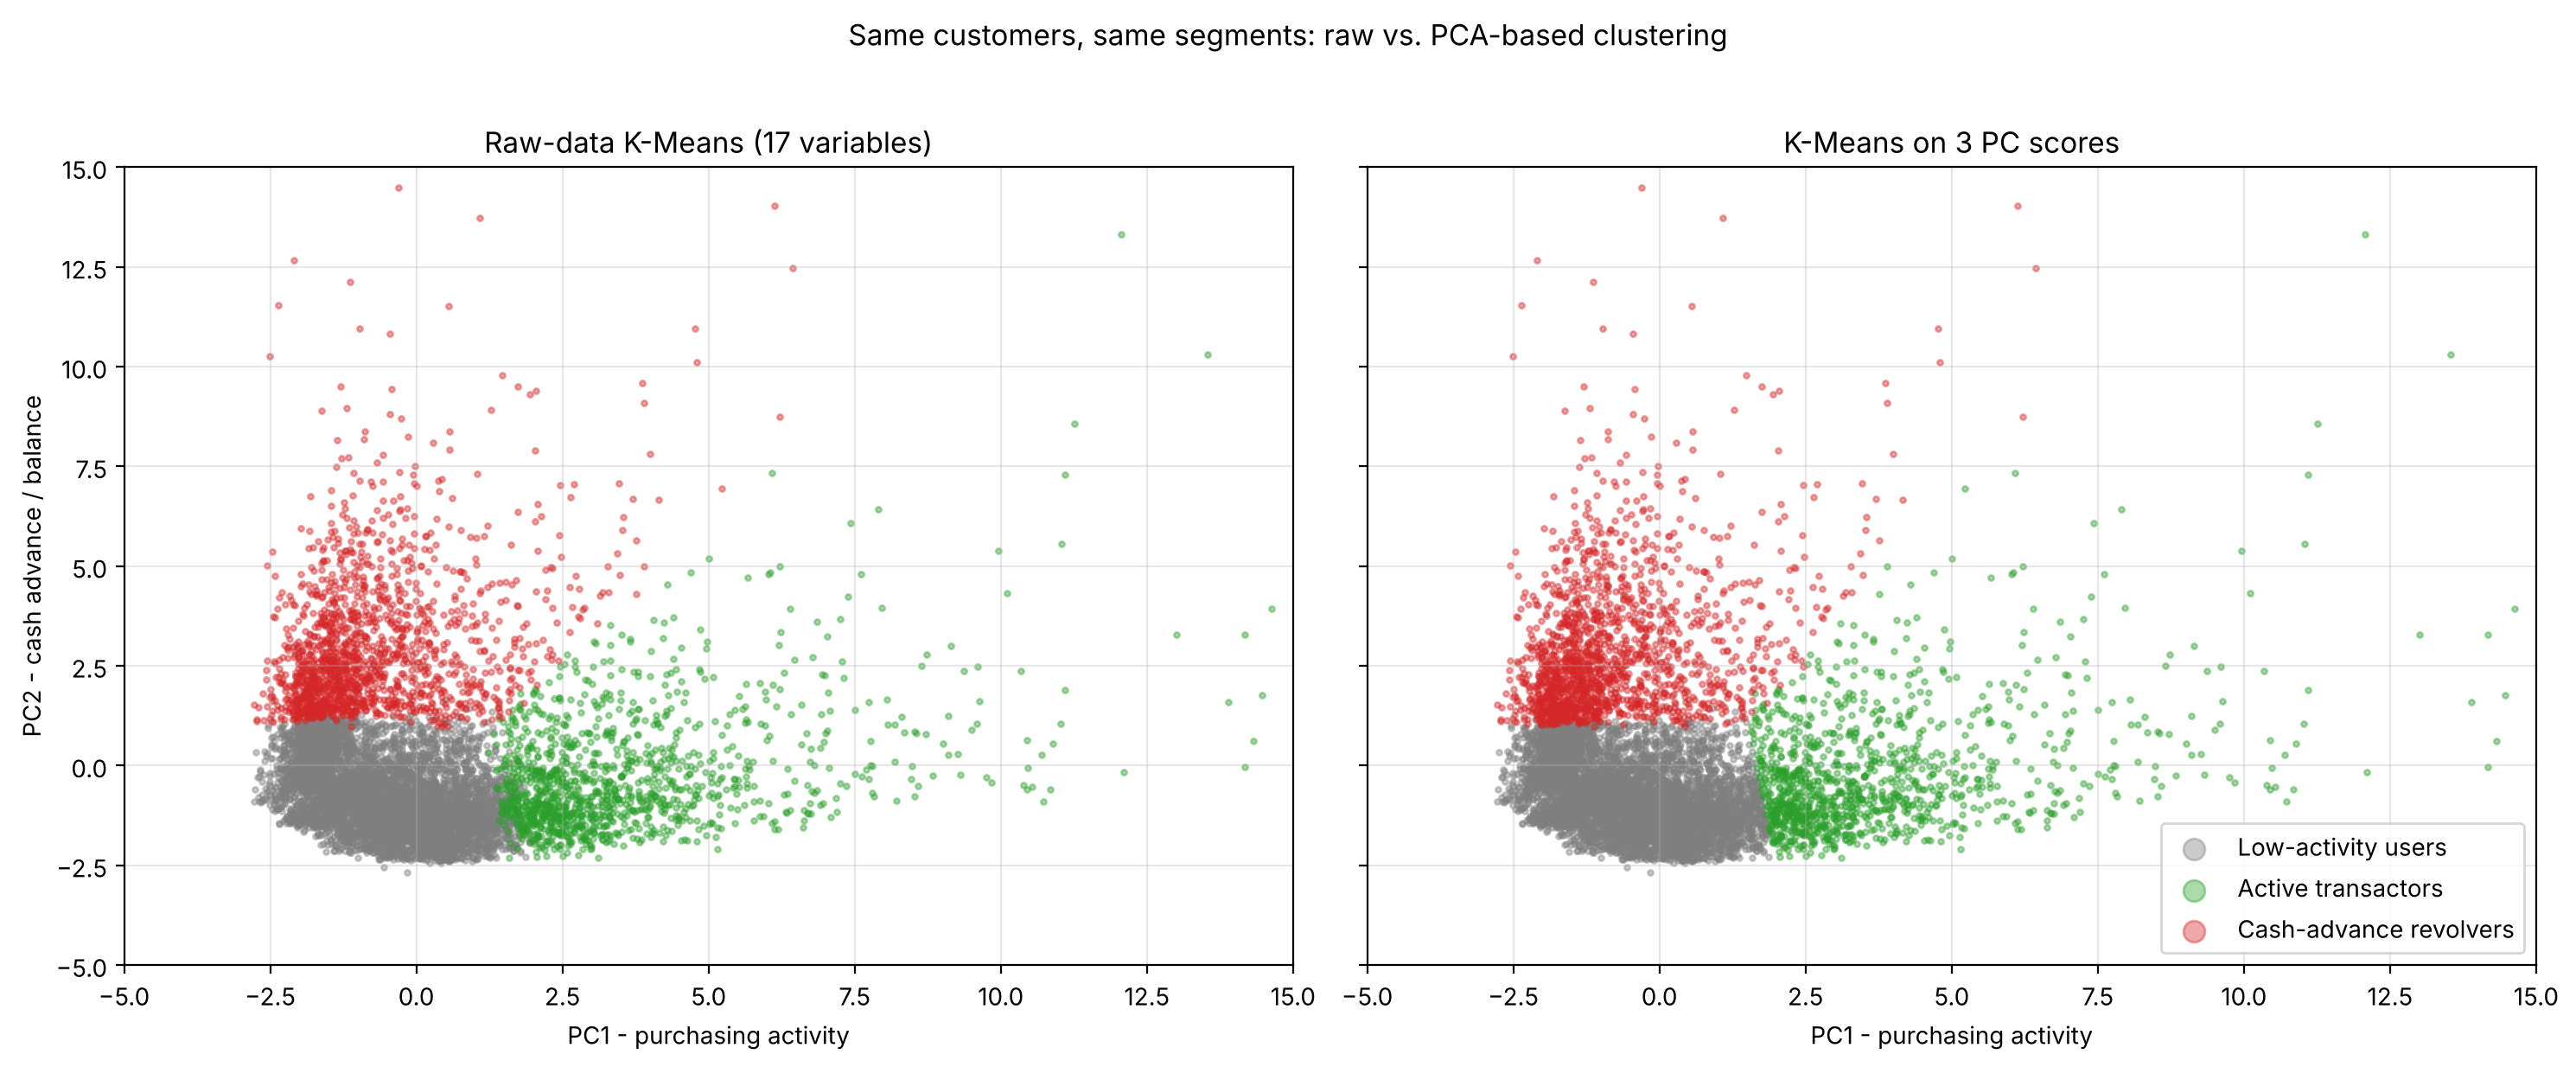

Customers assigned differently: 193 of 8950 (2.2%)


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
colors = {0: "tab:green", 1: "tab:gray", 2: "tab:red"}
for ax, lab, title in [(axes[0], labels_raw, "Raw-data K-Means (17 variables)"),
                       (axes[1], labels_pca, f"K-Means on {Q_MAIN} PC scores")]:
    for c in [1, 0, 2]:
        m = lab == c
        ax.scatter(scores_full[m, 0], scores_full[m, 1], s=5, alpha=0.4, color=colors[c], label=cluster_names[c])
    ax.set_title(title)
    ax.set_xlabel("PC1 - purchasing activity")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("PC2 - cash advance / balance")
axes[0].set_xlim(-5, 15)
axes[0].set_ylim(-5, 15)
axes[1].legend(markerscale=4)
plt.suptitle("Same customers, same segments: raw vs. PCA-based clustering", y=1.02)
plt.tight_layout()
plt.show()

n_diff = int((labels_raw != labels_pca).sum())
print(f"Customers assigned differently: {n_diff} of {len(labels_raw)} ({n_diff/len(labels_raw):.1%})")

## 5. PCA as a pre-step for Gaussian Mixture Models
The full GMM analysis is in the teammate's section; this is a short check on how PCA interacts with GMM.

GMM with full covariance matrices has to estimate a 17×17 covariance for each component. Our data makes that hard: one variable is a near-exact sum of two others (an almost singular covariance matrix), and many variables are proportions with large point masses at exactly 0 or 1. Both let GMM build extremely narrow components whose likelihood blows up.

,raw (17 vars),5 PCs,3 PCs
Components (k),,,
1,259336.0,158281.0,104726.0
2,137216.0,140016.0,93726.0
3,-109744.0,125296.0,88858.0
4,-166286.0,121355.0,87790.0
5,-193654.0,116607.0,85095.0
6,-233787.0,111377.0,84460.0
7,-270373.0,110669.0,83063.0
8,-299079.0,108089.0,82579.0


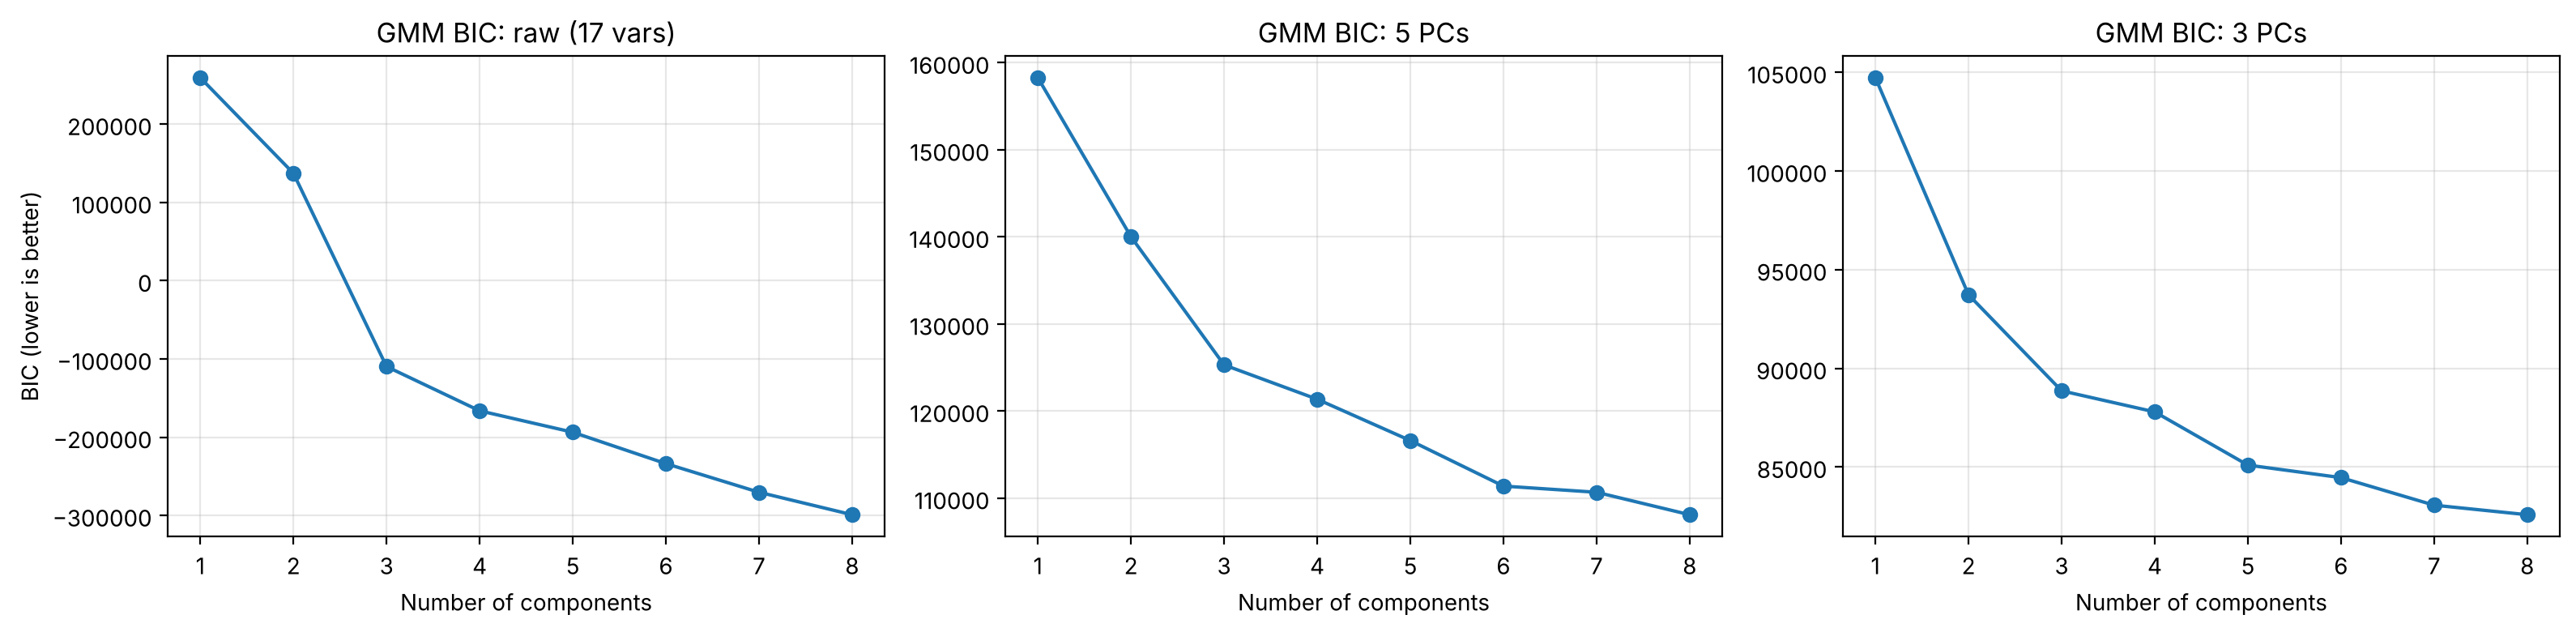

In [18]:
bic = {"raw (17 vars)": [], "5 PCs": [], "3 PCs": []}
inputs = {"raw (17 vars)": X_scaled.values,
          "5 PCs": PCA(5, random_state=RANDOM_STATE).fit_transform(X_scaled),
          "3 PCs": PCA(3, random_state=RANDOM_STATE).fit_transform(X_scaled)}
k_range = range(1, 9)
for name, Z in inputs.items():
    for k in k_range:
        g = GaussianMixture(n_components=k, covariance_type="full", random_state=RANDOM_STATE, n_init=3).fit(Z)
        bic[name].append(g.bic(Z))

bic_df = pd.DataFrame(bic, index=pd.Index(list(k_range), name="Components (k)"))
display(bic_df.round(0))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, name in zip(axes, bic_df.columns):
    ax.plot(bic_df.index, bic_df[name], marker="o")
    ax.set_title(f"GMM BIC: {name}")
    ax.set_xlabel("Number of components")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("BIC (lower is better)")
plt.tight_layout()
plt.show()

On the raw standardized data, BIC drops to huge **negative** values and keeps falling as components are added. That is the signature of degenerate, near-singular components (the likelihood is exploding), not real structure, so BIC can't be trusted to pick *k* there. On PC scores, the BIC values are on a sensible scale and decline more gradually.

PCA therefore makes GMM better behaved numerically. Choosing *k* for GMM, and comparing GMM against K-Means, is left to the GMM section.

## 6. Sensitivity check: skewed variables
The money variables are extremely right-skewed (a few customers have very large purchases, payments, etc.). PCA is driven by variance, so these extremes have a large influence. As a sensitivity check, we log-transform the dollar and count variables (`log(1 + x)`) before standardizing and repeat the PCA.

In [19]:
print("Skewness of the most skewed variables:")
print(data.skew().sort_values(ascending=False).head(8).round(1))

money_cols = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE",
              "CASH_ADVANCE_TRX", "PURCHASES_TRX", "CREDIT_LIMIT", "PAYMENTS", "MINIMUM_PAYMENTS"]
data_log = data.copy()
data_log[money_cols] = np.log1p(data_log[money_cols])
X_log = StandardScaler().fit_transform(data_log)
pca_log = PCA(random_state=RANDOM_STATE).fit(X_log)

sens = pd.DataFrame({
    "Cumulative variance (standardized)": cum_var[:7],
    "Cumulative variance (log + standardized)": np.cumsum(pca_log.explained_variance_ratio_)[:7],
}, index=[f"PC{i+1}" for i in range(7)])
display(sens.round(3))
print("Kaiser criterion (log version):", int((pca_log.explained_variance_ > 1).sum()), "PCs")

Skewness of the most skewed variables:
MINIMUM_PAYMENTS          13.9
ONEOFF_PURCHASES          10.0
PURCHASES                  8.1
INSTALLMENTS_PURCHASES     7.3
PAYMENTS                   5.9
CASH_ADVANCE_TRX           5.7
CASH_ADVANCE               5.2
PURCHASES_TRX              4.6
dtype: float64


,Cumulative variance (standardized),Cumulative variance (log + standardized)
PC1,0.273,0.339
PC2,0.476,0.558
PC3,0.564,0.652
PC4,0.639,0.726
PC5,0.701,0.792
PC6,0.759,0.842
PC7,0.808,0.883


Kaiser criterion (log version): 5 PCs


After the log transform, the first two components explain noticeably more variance (about 56% vs. 48%), because the extreme customers no longer dominate. The Kaiser criterion still keeps 5 PCs. The main analysis uses the same preprocessing as the rest of the project for consistency; whether to log-transform is a decision for the whole group, since it would also affect the K-Means and GMM results.

## 7. Summary: answer to Key Question 2
*Does prior dimension reduction enhance cluster stability and separation, or does it discard critical financial context?*

1. **PCA does not discard critical context.**
   - The two leading components have a clear financial meaning: PC1 is purchasing activity and PC2 is cash-advance borrowing with high balances.
   - Clusters found on as few as 2–3 PCs agree with the raw-data clusters at ARI > 0.9, and at ARI ≈ 0.96–0.98 with 5+ PCs.
   - The PCA-based segments have the same financial profiles: active transactors, cash-advance revolvers, low-activity users.
2. **PCA does not improve separation.** Measured fairly in the original variable space, the silhouette is about 0.25 with or without PCA. Higher silhouettes computed in PC space are an artifact of using fewer dimensions.
3. **PCA does improve stability.** Bootstrap stability rises as components are dropped. Raw-data K-Means collapses into a different partition in 32% of bootstrap resamples, compared with 4% using 3 PCs and 0% using 2 PCs.
4. **PCA helps GMM numerically.** It removes the redundant purchase variable and the near-singular directions that cause degenerate full-covariance GMM fits on the raw data.

**Bottom line:** reducing to the first 2–3 principal components keeps the risk-relevant structure (spending vs. cash-advance borrowing), produces the same customer segments, and finds them more reliably. The trade-off is that individual-variable detail (e.g., tenure, one-off vs. installment style) is pushed into later components that the clustering no longer sees.